In [27]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from joblib import load
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay, classification_report, RocCurveDisplay
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Configure base directory for both Google Colab and local environments
if "google.colab" in sys.modules:
    drive_path = Path("/content/drive/MyDrive/pytorch-projects/xor-function-neural-network")
    if not drive_path.exists():
        from google.colab import drive
        drive.mount("/content/drive")

    if drive_path.exists():
        base = str(drive_path)
    else:
        repo_name = "xor-function-neural-network"
        if not Path(repo_name).exists():
            !git clone https://github.com/nfor-ojong/xor-function-neural-network.git
        base = repo_name
else:
    cwd = Path.cwd()
    base = str(cwd.parent if cwd.name == "notebooks" else cwd)

os.makedirs(f"{base}/plots", exist_ok=True)
os.makedirs(f"{base}/test-results", exist_ok=True)

In [28]:
# Load test dataset
test = pd.read_csv(base + "/data/test.csv")

In [29]:
test.head() # inspect first 5 samples

,x1,x2,class
0,3.967433,5.580323,1
1,-5.324361,-4.574185,1
2,5.635016,3.301594,1
3,2.369043,-2.431812,0
4,3.607040,-3.598197,0


In [30]:
test.info() # test data information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      80 non-null     float64
 1   x2      80 non-null     float64
 2   class   80 non-null     int64  
dtypes: float64(2), int64(1)
memory usage: 2.0 KB


In [31]:
X_test = test.drop(columns=["class"]) # features
y_test = test["class"] # target

# Convert to tensors
X_test_t = torch.tensor(X_test.to_numpy(), dtype=torch.float32)
y_test_t = torch.tensor(y_test.to_numpy(), dtype=torch.float32).reshape(-1, 1) # make it 2 dimensional

In [32]:
# Load scaler object (StandardScaler)
scaler = load(base + "/model/standard_scaler.joblib")

# Transform X_test_t using scaler
X_test_t = scaler.transform(X_test_t)
X_test_t = torch.tensor(X_test_t, dtype=torch.float32) # convert again to tensor since StandardScaler returns np.array

# Display tensor shapes
print("X_test_t shape: ", X_test_t.shape)
print("y_test_t shape: ", y_test_t.shape)

X_test_t shape:  torch.Size([80, 2])
y_test_t shape:  torch.Size([80, 1])


In [33]:
# Build Neural Network exactly as it was defined during model training
model = nn.Sequential(
    nn.Linear(X_test_t.shape[1], 4),
    nn.ReLU(),
    nn.Linear(4, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)

# Load saved model parameters and use them to build the neural network
model.load_state_dict(torch.load(base + "/model/neural_network.pth", weights_only=True))

<All keys matched successfully>

In [34]:
# Make predictions using the model
model.eval() # put model in validation mode
with torch.no_grad(): # disable gradient calculations completely inside this block
  preds_test = model(X_test_t)

  # Compute probabilities by appling Sigmoid function to predictions (preds_test)
  probs = torch.sigmoid(preds_test)

In [35]:
# Set a decision threshold of 0.5.
# If prob >= 0.5, predict class 1; else predict class 0
y_preds_t = (probs >= 0.5)

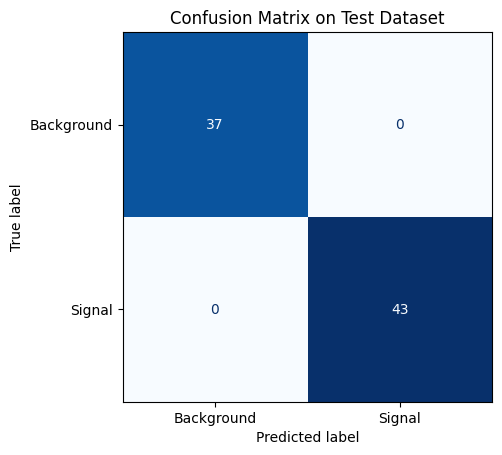

In [36]:
# Model Evaluation
# Confusion matrix
cm = ConfusionMatrixDisplay.from_predictions(
    y_test_t,
    y_preds_t,
    display_labels=["Background", "Signal"],
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion Matrix on Test Dataset")
plt.savefig(base + "/plots/confusion_matrix_on_test.png")
plt.show()

In [37]:
# Compute other performance metrics
accuracy = accuracy_score(y_test_t, y_preds_t)
precision = precision_score(y_test_t, y_preds_t)
recall = recall_score(y_test_t, y_preds_t)
f1 = f1_score(y_test_t, y_preds_t)

# Display performance metrics
print("TEST PERFORMANCE METRICS")
print("========================")
print(f"Test accuracy: {accuracy*100}%")
print(f"Test precision: {precision*100}%")
print(f"Test recall: {recall*100}%")
print(f"Test F1-score: {f1*100}%")

TEST PERFORMANCE METRICS
Test accuracy: 100.0%
Test precision: 100.0%
Test recall: 100.0%
Test F1-score: 100.0%


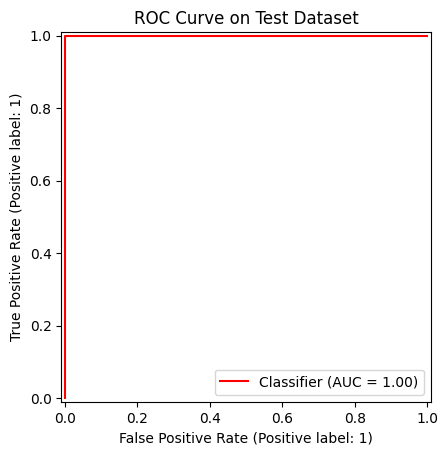

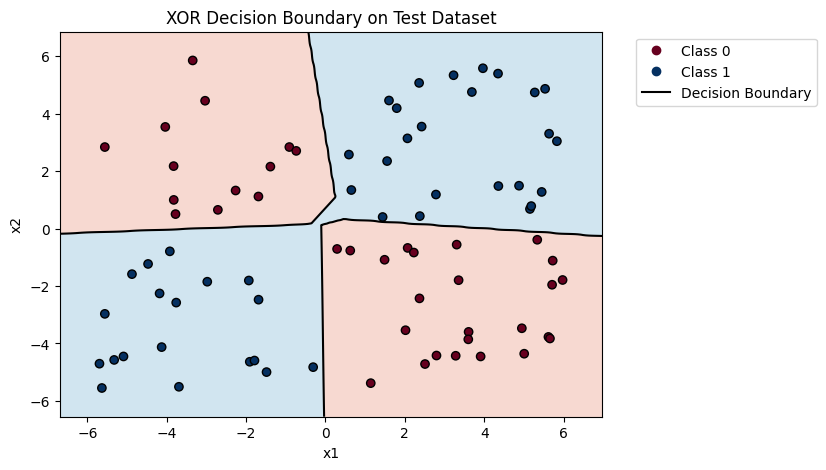

In [38]:
# Plot decision boundary and ROC curve
# ROC curve
RocCurveDisplay.from_predictions(y_test_t.numpy(), probs.numpy(), color="red")
plt.title("ROC Curve on Test Dataset")
plt.savefig(base + "/plots/roc_curve_on_test.png")
plt.show()

# Decision boundary plot (in original feature space)
x1_min, x1_max = X_test["x1"].min() - 1, X_test["x1"].max() + 1
x2_min, x2_max = X_test["x2"].min() - 1, X_test["x2"].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200),
                       np.linspace(x2_min, x2_max, 200))

grid = np.c_[xx1.ravel(), xx2.ravel()]
grid_scaled = torch.tensor(scaler.transform(grid), dtype=torch.float32)

with torch.no_grad():
    grid_probs = torch.sigmoid(model(grid_scaled)).reshape(xx1.shape).numpy()

plt.figure(figsize=(7, 5))
plt.contourf(xx1, xx2, grid_probs, levels=[0, 0.5, 1], cmap="RdBu", alpha=0.3)
plt.contour(xx1, xx2, grid_probs, levels=[0.5], colors="black", linewidths=1.5)
scatter = plt.scatter(X_test["x1"], X_test["x2"], c=y_test, cmap="RdBu", edgecolors="k")

handles, _ = scatter.legend_elements()
boundary_line = plt.Line2D([], [], color="black", linewidth=1.5)
plt.legend(
    handles + [boundary_line],
    ["Class 0", "Class 1", "Decision Boundary"],
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
)  # put legend outside the scatter plot

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("XOR Decision Boundary on Test Dataset")
plt.savefig(base + "/plots/decision_boundary_on_test.png", bbox_inches="tight")
plt.show()
